## this script investigates the collaobration frequency among different s&t groups

In [40]:
import pandas as pd
import itertools
import tqdm
import seaborn as sns
import string

In [2]:
author_path='../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl'
group_path='../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'
author_info_path='../../data/dropbox/LaborDivision/Data/deriveddata/matching/author_meta.csv'

In [3]:
author_df=pd.read_pickle(author_path)

In [4]:
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [5]:
group_df=pd.read_csv(group_path)
group_df=group_df[['Code','ST']].drop_duplicates()
group_df=group_df.replace(to_replace={'ST':{'Others':'Lagging'}})

In [6]:
group_df.ST.unique()

array(['Lagging', 'Developing', 'Advanced', 'Proficient'], dtype=object)

In [7]:
#merge authorship countries with nature index
pub_filter=author_df[['id','Code']].drop_duplicates().merge(group_df,on='Code')
#select unique cntry-group pair
pub_filter=pub_filter[['id','ST']].drop_duplicates()

In [8]:
pub_filter=pub_filter.groupby(['id'])['ST'].apply(list)

In [9]:
pub_filter=pub_filter.reset_index(name='type')

In [10]:
pub_filter

,id,type
0,29768070,"[Advanced, Proficient]"
1,29768104,[Advanced]
2,29768123,[Advanced]
3,29768126,[Advanced]
4,29768150,"[Advanced, Proficient]"
...,...,...
3502751,84634925,"[Proficient, Advanced]"
3502752,84634926,"[Advanced, Proficient]"
3502753,84634936,[Advanced]
3502754,84634941,[Advanced]


In [11]:
# create all possible combinations of list values
values = ['Advanced', 'Proficient', 'Developing', 'Lagging']
combinations = []
for i in range(1, 5):
    combinations += list(itertools.combinations(values, r=i))

# create dictionary to count frequency of each combination
freq_dict = {combo: 0 for combo in combinations}

# iterate through rows of dataframe and count frequency of each combination
for index, row in tqdm.tqdm(pub_filter.iterrows()):
    for combo in combinations:
        if set(row['type'])==set(combo):
            freq_dict[combo] += 1
            break
    else:
        print('not matched')


3502756it [04:35, 12719.64it/s]


In [19]:
df = pd.DataFrame.from_dict(freq_dict, orient='index', columns=['Value'])

In [21]:
df=df.sort_values(by='Value',ascending=False)

In [23]:
df['p']=df['Value']/df['Value'].sum()

In [29]:
df = df.reset_index()
df['color']='#BFBFBF'

In [35]:
df=df.rename(columns={'index':'type'})

In [37]:
df['color']=df.apply(lambda x: '#F2C12E' if 'Advanced' in x.type else x.color, axis=1)

In [41]:
df['label']=list(string.ascii_lowercase[:len(df)])

In [42]:
df

,type,Value,p,color,label
0,"(Advanced,)",1340224,0.382620,#F2C12E,a
1,"(Advanced, Proficient)",1268434,0.362125,#F2C12E,b
2,"(Advanced, Lagging)",249827,0.071323,#F2C12E,c
3,"(Advanced, Developing)",195060,0.055688,#F2C12E,d
4,"(Proficient,)",113857,0.032505,#BFBFBF,e
5,"(Proficient, Developing)",71140,0.020310,#BFBFBF,f
6,"(Proficient, Lagging)",66132,0.018880,#BFBFBF,g
7,"(Advanced, Proficient, Lagging)",47142,0.013459,#F2C12E,h
8,"(Advanced, Proficient, Developing)",43335,0.012372,#F2C12E,i
9,"(Developing, Lagging)",37227,0.010628,#BFBFBF,j


<AxesSubplot:xlabel='label', ylabel='p'>

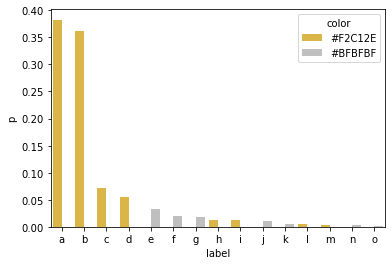

In [44]:
colormap={'#BFBFBF':'#BFBFBF','#F2C12E':'#F2C12E'}
sns.barplot(x='label',y='p',hue='color', data=df, palette=colormap)

In [27]:
df.index

Index([                                      ('Advanced',),
                                ('Advanced', 'Proficient'),
                                   ('Advanced', 'Lagging'),
                                ('Advanced', 'Developing'),
                                           ('Proficient',),
                              ('Proficient', 'Developing'),
                                 ('Proficient', 'Lagging'),
                     ('Advanced', 'Proficient', 'Lagging'),
                  ('Advanced', 'Proficient', 'Developing'),
                                 ('Developing', 'Lagging'),
                                              ('Lagging',),
                     ('Advanced', 'Developing', 'Lagging'),
       ('Advanced', 'Proficient', 'Developing', 'Lagging'),
                                           ('Developing',),
                   ('Proficient', 'Developing', 'Lagging')],
      dtype='object')

In [50]:
18684905*0.84

15695320.2